# Explore SNOWPACK stratigraphy

Edit the site, simulation, and water year in the load cell. The cell lists the available
runs for that site so you can copy a filename stem into `simulation`. To use an output
elsewhere, set `custom_pro_path`. Water years start on October 1 of the previous calendar
year. Use `date_window` to zoom into a season or select any date range.

Run the last cell again after changing `variable` to draw one time series from the loaded data.
The plot uses the reported layer heights above ground and the timestamps as written in the file.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'figures/notebooks/snowpack_profiles.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Start the notebook from the manuscript repository.')
sys.path.insert(0, str(root / 'figures/notebooks'))

from snowpack_profiles import plot_profiles, read_profiles, save_figure, water_year_window

In [5]:
model_root = Path('/home/cassie/python/models/run_snowpack/sites')
site = 'ppsa'
simulation = 'met_hrrrak_ppsa2_WY2025_base_with_met_station'

water_year = 2025
date_window = None  # Example: ('2024-10-01', '2025-07-01').
custom_pro_path = None  # Example: Path('/path/to/simulation.pro')
sample_hours = 3  # Use 1 for hourly output or a larger number for long windows.

output_folder = model_root / site / 'output'
print(f'Available runs for {site.upper()}:')
print('\n'.join(path.stem for path in sorted(output_folder.glob('*.pro'))))
pro_path = Path(custom_pro_path) if custom_pro_path else output_folder / f'{simulation}.pro'
window = tuple(map(pd.Timestamp, date_window)) if date_window else water_year_window(water_year)
profiles, cadence = read_profiles(pro_path, *window, sample_hours=sample_hours)
print(f'Loaded {len(profiles):,} profiles from {pro_path.name} '
      f'({profiles[0].time} to {profiles[-1].time}).')

Available runs for PPSA:
hrrrak_lapserate_ppsa_WY2020-WY2025_base
hrrrak_lapserate_ppsa_WY2020-WY2025_base_thresh07
hrrrak_lapserate_ppsa_WY2020-WY2025_base_thresh10
hrrrak_lapserate_ppsa_WY2020-WY2025_soil
hrrrak_lapserate_ppsa_WY2020-WY2025_soil_thresh07
hrrrak_ppsa2_WY2025_base
hrrrak_ppsa_WY2020-WY2025_base
met_hrrrak_lapserate_ppsa_WY2020-WY2025_base
met_hrrrak_lapserate_ppsa_WY2020-WY2025_base_thresh07
met_hrrrak_lapserate_ppsa_WY2020-WY2025_base_thresh10
met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil
met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil_thresh07
met_hrrrak_ppsa2_WY2025_base_with_met_station
met_hrrrak_ppsa_WY2020-WY2025_base
met_hrrrak_ppsa_WY2023-WY2025_base


Loaded 2,184 profiles from met_hrrrak_ppsa2_WY2025_base_with_met_station.pro (2024-10-01 05:00:00 to 2025-07-01 00:00:00).


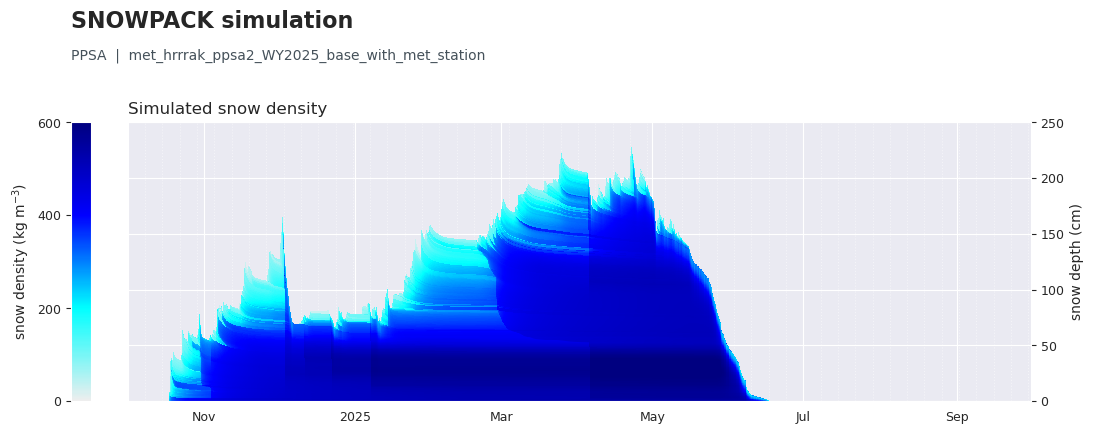

In [6]:
variable = 'density'  # density, temperature, liquid_water, or grain_type
depth_max = None  # cm, or None to fit the loaded profiles
color_limits = None  # Example for density: (50, 550)

fig = plot_profiles(profiles, cadence, (variable,), window,
                    heading='SNOWPACK simulation',
                    subtitle=f'{site.upper()}  |  {pro_path.stem}',
                    depth_max=depth_max, color_limits={variable: color_limits})
plt.show()

[SNOWPACK PRO format and grain codes](https://snowpack.slf.ch/doc-dev/html/snowpackio.html) · [NiViz grain-color and crust conventions](https://niviz.org/niviz/dist/doc/files/lib_graphs_gradient.js.html)